# 02b · RetinaNet (one-stage, anchor-based)

Rubric: *One-stage Anchor-based*.

We train RetinaNet with exactly the same protocol as Faster R-CNN (notebook 02):
- 3-fold GroupKFold by video clip (`splits.json`);
- every 20th frame for training, every 10th frame for validation;
- 640 px input, 12 epochs;
- out-of-fold (OOF) COCO metrics, with ignored regions marked as `iscrowd=1`.

Training and evaluation code is shared with Faster R-CNN and lives in `tv_train.py`. Data loading is in `tv_dataset.py`, metrics and logging in `common.py`.

## 1. Run settings
- `MODE`: `"quick"` is a few-minute smoke test of every code path; `"full"` is the real run.
- `EXPERIMENT`: one experiment name from section 3, or a list that is trained one after another.
- `FOLDS`: which folds to train in this session.
- `RUN_ANALYSIS`: run the anchor analysis, error analysis and comparison with Faster R-CNN.
- `BEST_ANCHORS`: the anchor setting that later experiments build on.
- `FRCNN_EXPERIMENT`: which Faster R-CNN run to compare with (`auto` = best by OOF mAP).

In [1]:
MODE = "full"
EXPERIMENT = ["retina_base", "retina_anch05", "retina_g1"]
FOLDS = [0, 1, 2]
RUN_ANALYSIS = True
ANALYSIS_EXPERIMENT = "auto"
BEST_ANCHORS = "retina_anch05"
FRCNN_EXPERIMENT = "auto"

## 2. Setup
Get the shared modules: from the repository folder if the notebook runs locally, otherwise by cloning the GitHub repo (on Kaggle). `git clone` always gets the latest commit.

In [2]:
import os
import sys
import time
import urllib.request
from pathlib import Path

import shutil
import subprocess

REPO_GIT = "https://github.com/KaplyshOlha/hw-2.git"
REPO_RAW = "https://raw.githubusercontent.com/KaplyshOlha/hw-2/main/notebooks/"
SRC_FILES = ["common.py", "tv_dataset.py", "tv_train.py", "splits.json", "anchors.json"]
SRC = next((Path(p) for p in [".", "notebooks"] if all((Path(p) / f).exists() for f in SRC_FILES)), None)
if SRC is None:
    shutil.rmtree("/tmp/hw2_repo", ignore_errors=True)
    subprocess.run(["git", "clone", "-q", "--depth", "1", REPO_GIT, "/tmp/hw2_repo"], check=True)
    SRC = Path("/tmp/hw2_repo/notebooks")
    print("repo commit:", subprocess.run(["git", "-C", "/tmp/hw2_repo", "log", "-1", "--format=%h %ad %s", "--date=iso"],
                                         capture_output=True, text=True).stdout.strip())
sys.path.insert(0, str(SRC.resolve()))

repo commit: 6c4bb90 2026-11-09 13:48:46 +0200 3rd and 4th notebooks with output


Imports, output paths and device. Modules are reloaded so that an old `tv_train.py` cannot stay in memory. FULL mode stops if no GPU is attached.

In [3]:
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from IPython.display import display

import importlib
import common
import tv_dataset
import tv_train as tvt

for m in (common, tv_dataset, tvt):
    importlib.reload(m)

assert MODE in ("quick", "full")
assert hasattr(tvt, "anchor_match_stats") and ".cpu()" in Path(tvt.__file__).read_text(), \
    f"old tv_train.py loaded from {tvt.__file__}: push the new version to GitHub, then Restart & Run All"
print("tv_train:", tvt.__file__)
WORK = Path("/kaggle/working") if Path("/kaggle/working").exists() else Path("outputs")
RUN_ROOT = WORK / ("runs" if MODE == "full" else "runs_quick")
RESULTS = WORK / ("results.csv" if MODE == "full" else "results_quick.csv")
IMG_DIR = WORK / "images"
IMG_DIR.mkdir(parents=True, exist_ok=True)
INPUT_ROOT = os.environ.get("HW2_INPUTS", "/kaggle/input")
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if MODE == "full":
    assert DEVICE.type == "cuda", "FULL mode needs a GPU (Settings -> Accelerator -> GPU T4)"
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 130, "savefig.bbox": "tight"})
print(f"MODE={MODE} EXPERIMENT={EXPERIMENT} FOLDS={FOLDS} "
      f"device={torch.cuda.get_device_name(0) if DEVICE.type == 'cuda' else 'cpu'} src={SRC}")

tv_train: /tmp/hw2_repo/notebooks/tv_train.py
MODE=full EXPERIMENT=['retina_base', 'retina_anch05', 'retina_g1'] FOLDS=[0, 1, 2] device=Tesla T4 src=/tmp/hw2_repo/notebooks


Copy finished folds and `results.csv` from earlier notebook versions attached as inputs, so finished training is reused, not repeated.

In [4]:
tvt.restore_from_inputs(RUN_ROOT, RESULTS, INPUT_ROOT, name=RUN_ROOT.name);

restored 9 fold dirs from /kaggle/input


## 3. Experiments
**Training setup** (same as Faster R-CNN): SGD with momentum 0.9 and weight decay 1e-4, batch 8, LR 0.01 with 200 warmup iterations, LR ×0.1 at epochs 8 and 11, mixed precision, horizontal flip. Ignored regions are painted gray in training images; validation images are left as they are, like the test images. Inference: `score_thresh=0.001`, at most 300 detections per image, NMS 0.5.

**Model:** `retinanet_resnet50_fpn` with COCO weights. Everything is kept from COCO except the last classification layer (8 classes). Its bias starts at a prior of 0.01, so at the start every anchor is predicted as background.

Each experiment changes one thing:

| experiment | change | why |
|---|---|---|
| `retina_base` | default anchors, 32–512 px | baseline |
| `retina_anch05` | anchors ×0.5 → 16–406 px | median object is 15 px at 640; default anchors are too big |
| `retina_g1` | ×0.5 anchors + focal loss γ 2 → 1 | the required loss experiment |
| `retina_kmeans` *(not trained)* | k-means anchors per fold, 4–55 px | the anchor analysis in section 5 shows it is the worst option |
| `retina_iou43`, `retina_a05`, `retina_giou`, `retina_anch025`, `retina_tuned` *(not trained)* | IoU thresholds 0.4/0.3, focal α 0.5, GIoU loss, anchors ×0.25, combined | defined for completeness; no GPU time left |

We do not tune aspect ratios: k-means on the boxes gives about (0.5, 1, 2), which are already the defaults.

In [5]:
BASE = tvt.Config(experiment="retina_base", model="retinanet", anchors_json=str(SRC / "anchors.json"),
                  notes="torchvision RetinaNet defaults, COCO-pretrained, 640px")
EXPERIMENTS = {"retina_base": BASE}
EXPERIMENTS["retina_anch05"] = tvt.make_config(
    BASE, experiment="retina_anch05", anchor_key="x0.5", notes="anchors x0.5 (16-406)")
EXPERIMENTS["retina_kmeans"] = tvt.make_config(
    BASE, experiment="retina_kmeans", anchor_key="kmeans", notes="per-fold k-means anchors (4-55)")
EXPERIMENTS["retina_anch025"] = tvt.make_config(
    BASE, experiment="retina_anch025", anchor_key="x0.25", notes="anchors x0.25 (8-203)")
BEST = EXPERIMENTS[BEST_ANCHORS]
EXPERIMENTS["retina_iou43"] = tvt.make_config(
    BEST, experiment="retina_iou43", fg_iou_thresh=0.4, bg_iou_thresh=0.3,
    notes=f"{BEST_ANCHORS} + fg/bg IoU 0.4/0.3")
EXPERIMENTS["retina_g1"] = tvt.make_config(
    BEST, experiment="retina_g1", focal_gamma=1.0, notes=f"{BEST_ANCHORS} + focal gamma 1")
EXPERIMENTS["retina_a05"] = tvt.make_config(
    BEST, experiment="retina_a05", focal_alpha=0.5, notes=f"{BEST_ANCHORS} + focal alpha 0.5")
EXPERIMENTS["retina_giou"] = tvt.make_config(
    BEST, experiment="retina_giou", retina_reg_loss="giou", notes=f"{BEST_ANCHORS} + GIoU box loss")
TUNED_CHANGES = dict(fg_iou_thresh=0.4, bg_iou_thresh=0.3, focal_gamma=1.0)
EXPERIMENTS["retina_tuned"] = tvt.make_config(
    BEST, experiment="retina_tuned", **TUNED_CHANGES, notes=f"{BEST_ANCHORS} + {TUNED_CHANGES}")

QUICK = dict(epochs=2, max_iters=15, batch_size=2, train_stride=100, eval_stride=200,
             warmup_iters=10, milestones=(1,), fps_warmup=3, fps_iters=10)


def get_cfg(name):
    c = EXPERIMENTS[name]
    return tvt.make_config(c, **QUICK) if MODE == "quick" else c


RUN_LIST = [EXPERIMENT] if isinstance(EXPERIMENT, str) else list(EXPERIMENT)
RUN_LIST = RUN_LIST[:1] if MODE == "quick" else RUN_LIST
assert all(n in EXPERIMENTS for n in RUN_LIST), f"unknown experiment in {RUN_LIST}"
cfg = get_cfg(RUN_LIST[0])
pd.Series({k: v for k, v in cfg.key().items() if v != tvt.Config().key().get(k)}, name="changed vs defaults", dtype=object)

experiment    retina_base
model           retinanet
Name: changed vs defaults, dtype: object

## 4. Data and folds
Load all labelled frames (train + val) and the fixed 3-fold split by clip, and show how many frames each fold uses.

In [6]:
common.seed_everything()
images, anns = common.load_gt(cache="/tmp/gt_cache.pkl")
splits = common.load_splits(SRC / "splits.json")
pd.DataFrame([{"fold": f["fold"], "train_clips": len(f["train_clips"]), "val_clips": len(f["val_clips"]),
               "train_frames": len(common.fold_images(images, splits, f["fold"], "train", cfg.train_stride)),
               "val_frames": len(common.fold_images(images, splits, f["fold"], "val", cfg.eval_stride))}
              for f in splits["folds"]]).set_index("fold")

,train_clips,val_clips,train_frames,val_frames
fold,,,,
0,42,21,922,912
1,42,21,923,913
2,42,21,923,909


## 5. Anchors vs object sizes (no training needed)
RetinaNet decides which anchors are positive only by IoU with the ground-truth (GT) box:
- IoU ≥ 0.5 → positive; IoU < 0.4 → negative; in between → ignored.
- If a GT box has no anchor with IoU ≥ 0.5, its single best anchor is still made positive (a "low-quality match").

Here we run torchvision's own matcher on the GT boxes of fold 0 for each anchor setting. This shows, before any training, how many objects of each size actually get positive anchors. k-means anchors are fitted only on the training part of the fold.

In [7]:
ANCHOR_VARIANTS = {"default": "retina_base", "x0.5": "retina_anch05", "x0.25": "retina_anch025", "kmeans": "retina_kmeans"}
DO_ANALYSIS = RUN_ANALYSIS or MODE == "quick"
if DO_ANALYSIS:
    t0 = time.time()
    atr, _ = tvt.make_datasets(get_cfg("retina_base"), images, anns, splits, 0, precache=False)
    agt, aimg = tvt.anchor_match_stats({k: get_cfg(v) for k, v in ANCHOR_VARIANTS.items()}, atr, fold=0,
                                       thresholds=((0.5, 0.4), (0.4, 0.3)),
                                       max_images=300 if MODE == "full" else 30)
    g05 = agt[agt["fg"] == 0.5]
    natural = g05.pivot_table(index="size_bin", columns="variant", values="natural_pos", aggfunc="mean", observed=True)
    natural.index = natural.index.astype(str)
    natural.loc["all"] = g05.groupby("variant")["natural_pos"].mean()
    pos = agt.pivot_table(index="size_bin", columns=["variant", "fg"], values="n_pos", aggfunc="mean", observed=True)
    pos.index = pos.index.astype(str)
    pos.loc["all"] = agt.groupby(["variant", "fg"])["n_pos"].mean()
    imb = aimg.groupby(["variant", "fg"])[["anchors", "pos", "between", "neg"]].mean()
    imb["neg_per_pos"] = imb["neg"] / imb["pos"].clip(lower=1)
    n_gt = g05[g05["variant"] == "default"].groupby("size_bin", observed=True).size()
    natural.insert(0, "n_gt", n_gt.rename(index=str).reindex(natural.index))
    natural.loc["all", "n_gt"] = n_gt.sum()
    print(f"{int(n_gt.sum())} GT boxes on {(aimg['variant'] == 'default').sum() // 2} frames, {time.time() - t0:.0f}s")
    print("Share of GT boxes with at least one anchor at IoU >= 0.5 (by GT size at 640 px):")
    display(natural[["n_gt"] + list(ANCHOR_VARIANTS)].round(3))
    print("Mean positive anchors per GT box (fg = 0.5 / 0.4):")
    display(pos[[c for c in pos.columns if c[0] in ANCHOR_VARIANTS]].reindex(columns=list(ANCHOR_VARIANTS), level=0).round(2))
    print("Anchors per frame and foreground/background imbalance:")
    display(imb.reindex(list(ANCHOR_VARIANTS), level=0).round(1))

12652 GT boxes on 308 frames, 55s
Share of GT boxes with at least one anchor at IoU >= 0.5 (by GT size at 640 px):


variant,n_gt,default,x0.5,x0.25,kmeans
size_bin,,,,,
<8,1221.0,0.000,0.000,0.157,0.151
8-16,5087.0,0.000,0.408,0.539,0.187
16-32,4904.0,0.377,0.980,0.531,0.138
32-64,1303.0,0.998,0.995,0.519,0.036
64-128,136.0,1.000,1.000,0.706,0.037
>128,1.0,1.000,1.000,1.000,0.000
all,12652.0,0.260,0.657,0.499,0.147


Mean positive anchors per GT box (fg = 0.5 / 0.4):


variant  default          x0.5       x0.25       kmeans      
fg           0.4    0.5    0.4   0.5   0.4   0.5    0.4   0.5
size_bin                                                     
<8          6.93   6.93   1.14  1.14  1.72  1.12   1.81  1.26
8-16        6.94   6.94   3.40  1.61  5.10  2.30   2.20  1.38
16-32      10.19   5.28  17.22  6.33  4.92  2.10   1.77  1.23
32-64      65.84  24.06  20.27  6.70  4.83  1.98   1.26  1.11
64-128     82.54  27.93  20.51  6.86  5.85  2.68   1.10  1.02
>128      111.00  32.00  27.00  9.00  6.00  2.00   1.00  1.00
all        15.09   8.29  10.46  3.98  4.68  2.08   1.89  1.28

Anchors per frame and foreground/background imbalance:


anchors    pos  between      neg  neg_per_pos
variant fg                                                
default 0.4  46035.0  619.8    702.2  44713.1         72.1
        0.5  46035.0  340.5    279.3  45415.2        133.4
x0.5    0.4  46035.0  429.7    630.7  44974.6        104.7
        0.5  46035.0  163.4    266.3  45605.3        279.2
x0.25   0.4  46035.0  192.4    280.8  45561.7        236.8
        0.5  46035.0   85.4    107.0  45842.6        536.7
kmeans  0.4  46035.0   77.5     71.3  45886.2        592.3
        0.5  46035.0   52.5     25.0  45957.5        875.8

Left: share of GT boxes that have an anchor with IoU ≥ 0.5. Right: positive anchors per GT box (solid: thresholds 0.5/0.4, dashed: 0.4/0.3).

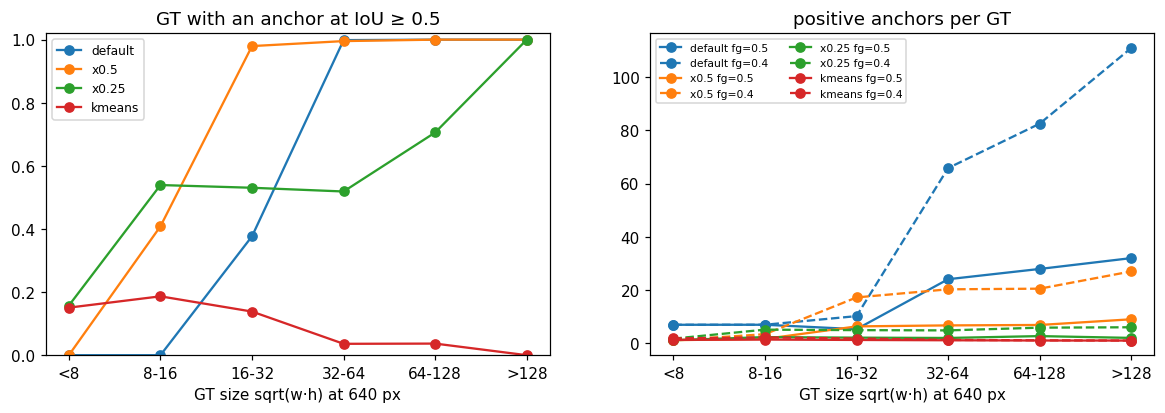

In [8]:
if DO_ANALYSIS:
    fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
    for i, v in enumerate(ANCHOR_VARIANTS):
        c = f"C{i}"
        ax[0].plot(natural.index[:-1].astype(str), natural[v].iloc[:-1], marker="o", color=c, label=v)
        for fg, ls in [(0.5, "-"), (0.4, "--")]:
            if (v, fg) in pos.columns:
                ax[1].plot(pos.index[:-1].astype(str), pos[(v, fg)].iloc[:-1], marker="o", ls=ls, color=c,
                           label=f"{v} fg={fg}")
    ax[0].set_title("GT with an anchor at IoU ≥ 0.5")
    ax[1].set_title("positive anchors per GT")
    for a in ax:
        a.set_xlabel("GT size sqrt(w·h) at 640 px")
    ax[0].set_ylim(0, 1.02)
    ax[0].legend(fontsize=8)
    ax[1].legend(fontsize=7, ncol=2)
    fig.savefig(IMG_DIR / "02b_retina_anchor_matching.png")
    plt.show()

**Results (anchors).** 12,652 GT boxes on 308 frames.
- **Default anchors (32–512 px) miss small objects completely.** Objects under 16 px (51% of all boxes) never have an anchor with IoU ≥ 0.5. Overall only 26% of boxes do.
- **Anchors ×0.5 raise this to 66%:** 41% for 8–16 px and 98% for 16–32 px, while large objects stay covered. The cost: large objects get fewer positives (32–64 px: 24 → 7 per box).
- **Anchors ×0.25** help the smallest objects a bit more, but 16–128 px objects drop to about 52%.
- **k-means is the worst (15% overall).** It puts 15–55 px anchors on the coarse levels P5–P7 (stride 32–128), where the anchor grid is too sparse to line up with small objects. **Lesson: anchor size must match the stride of its level, not only the box sizes.** So we did not train k-means and chose ×0.5 as `BEST_ANCHORS`.
- **Strong imbalance:** 46,035 anchors per frame, but only 163–340 positives. That is 133–279 negatives per positive (876 for k-means). This is the problem focal loss is built for.

## 6. Training and prediction
For each experiment and each fold: train (finished folds are skipped, interrupted ones resume from `last.pt`), predict the validation frames and measure FPS. In QUICK mode the run is first stopped after epoch 1 on purpose, to test resuming.

In [9]:
t0 = time.time()
if MODE == "quick":
    try:
        tvt.run_experiment(tvt.make_config(cfg, stop_after_epoch=1), images, anns, splits, FOLDS[:1],
                           RUN_ROOT, RESULTS, DEVICE)
    except tvt.Interrupted as e:
        print("resume test:", e)
all_metrics = {}
for name in RUN_LIST:
    all_metrics[name] = tvt.run_experiment(get_cfg(name), images, anns, splits, FOLDS, RUN_ROOT, RESULTS, DEVICE,
                                           require_all_folds=(MODE == "full"))
    print(f"{name} finished, {(time.time() - t0) / 60:.1f} min since start")

[retina_base] fold 0: already done, skipped
[retina_base] fold 1: already done, skipped
[retina_base] fold 2: already done, skipped
retina_base finished, 8.6 min since start
[retina_anch05] fold 0: already done, skipped
[retina_anch05] fold 1: already done, skipped
[retina_anch05] fold 2: already done, skipped
retina_anch05 finished, 16.1 min since start
[retina_g1] fold 0: already done, skipped
[retina_g1] fold 1: already done, skipped
[retina_g1] fold 2: already done, skipped
retina_g1 finished, 23.7 min since start


Metrics of the experiments in this run: per fold, mean ± std over folds, and pooled out-of-fold (`oof`), plus OOF AP per class.

In [10]:
MAIN = ["mAP", "AP50", "AP75", "AP_small", "AP_medium", "AP_large", "AR500"]
PER_CLASS = [f"AP_{c}" for c in common.CLASSES]
for name, metrics in all_metrics.items():
    if metrics is not None:
        print(name)
        display(metrics[MAIN].round(4))
        display(metrics.loc[["oof"], PER_CLASS].round(4))

retina_base


,mAP,AP50,AP75,AP_small,AP_medium,AP_large,AR500
0,0.0774,0.1504,0.0736,0.0068,0.0488,0.2379,0.1863
1,0.0721,0.1541,0.0646,0.0068,0.0543,0.2219,0.1698
2,0.0776,0.1719,0.0641,0.0073,0.0481,0.2129,0.2032
mean,0.0757,0.1588,0.0674,0.0070,0.0504,0.2242,0.1864
std,0.0026,0.0094,0.0043,0.0002,0.0028,0.0104,0.0136
oof,0.0707,0.1497,0.0620,0.0067,0.0481,0.2135,0.1844


,AP_person,AP_bicycle,AP_car,AP_van,AP_truck,AP_tricycle,AP_bus,AP_motor
oof,0.0658,0.0037,0.2201,0.0606,0.0183,0.06,0.1106,0.0333


retina_anch05


,mAP,AP50,AP75,AP_small,AP_medium,AP_large,AR500
0,0.0745,0.1727,0.0557,0.0268,0.0668,0.1862,0.2134
1,0.0863,0.2022,0.0663,0.0161,0.0789,0.2005,0.2085
2,0.0886,0.2185,0.0597,0.0194,0.0759,0.1931,0.2467
mean,0.0831,0.1978,0.0605,0.0207,0.0739,0.1933,0.2229
std,0.0062,0.0189,0.0043,0.0045,0.0051,0.0058,0.0170
oof,0.0798,0.1910,0.0574,0.0181,0.0709,0.1913,0.2216


,AP_person,AP_bicycle,AP_car,AP_van,AP_truck,AP_tricycle,AP_bus,AP_motor
oof,0.0889,0.0067,0.2792,0.0646,0.0162,0.0648,0.072,0.0486


retina_g1


,mAP,AP50,AP75,AP_small,AP_medium,AP_large,AR500
0,0.0810,0.1861,0.0625,0.0255,0.0684,0.1987,0.2160
1,0.0889,0.2081,0.0690,0.0172,0.0818,0.1992,0.2070
2,0.0928,0.2275,0.0652,0.0198,0.0794,0.2023,0.2439
mean,0.0875,0.2072,0.0656,0.0209,0.0765,0.2000,0.2223
std,0.0049,0.0169,0.0027,0.0035,0.0058,0.0016,0.0157
oof,0.0831,0.1988,0.0609,0.0187,0.0739,0.1961,0.2207


,AP_person,AP_bicycle,AP_car,AP_van,AP_truck,AP_tricycle,AP_bus,AP_motor
oof,0.0883,0.0068,0.2816,0.0675,0.0151,0.0719,0.0865,0.0502


## 7. RetinaNet experiments compared
The latest logged run of each RetinaNet experiment from `results.csv`.

In [11]:
names = [n for n in EXPERIMENTS if (RUN_ROOT / n).exists()]
summ = tvt.summary(RESULTS, model="retinanet", experiments=names)
num = summ.select_dtypes("number").columns
summ[num] = summ[num].where(summ[num] >= 0)
if len(summ):
    table = pd.DataFrame({m: summ[f"{m}_oof"].round(4) for m in ["mAP", "AP50", "AP75", "AP_small", "AP_medium", "AP_large", "AR500"]})
    table["mAP mean±std"] = [f"{a:.4f} ± {b:.4f}" for a, b in zip(summ["mAP_mean"], summ["mAP_std"])]
    table["FPS"] = summ["fps"].round(1)
    table["train min/fold"] = summ["train_min"].round(1)
    table.to_csv(WORK / "02b_retina_comparison.csv")
    display(table)
    display(summ[[c for c in PER_CLASS if c in summ]].round(4))

,mAP,AP50,AP75,AP_small,AP_medium,AP_large,AR500,mAP mean±std,FPS,train min/fold
experiment,,,,,,,,,,
retina_base,0.0707,0.1497,0.0620,0.0067,0.0481,0.2135,0.1844,0.0757 ± 0.0026,22.4,7.1
retina_anch05,0.0798,0.1910,0.0574,0.0181,0.0709,0.1913,0.2216,0.0831 ± 0.0062,22.2,7.1
retina_g1,0.0831,0.1988,0.0609,0.0187,0.0739,0.1961,0.2207,0.0875 ± 0.0049,22.5,7.1


,AP_person,AP_bicycle,AP_car,AP_van,AP_truck,AP_tricycle,AP_bus,AP_motor
experiment,,,,,,,,
retina_base,0.0658,0.0037,0.2201,0.0606,0.0183,0.0600,0.1106,0.0333
retina_anch05,0.0889,0.0067,0.2792,0.0646,0.0162,0.0648,0.0720,0.0486
retina_g1,0.0883,0.0068,0.2816,0.0675,0.0151,0.0719,0.0865,0.0502


Main metrics (error bars = std over folds) and OOF AP per class.

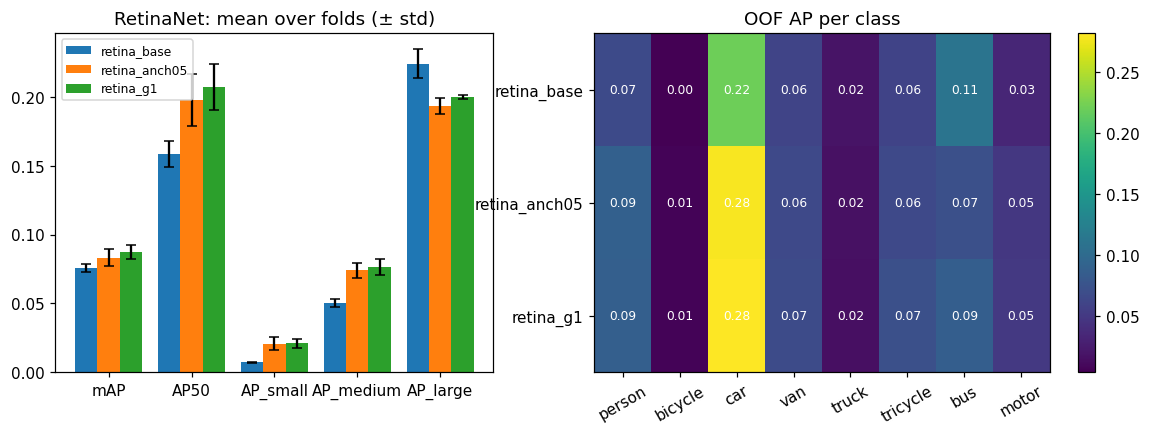

In [12]:
if len(summ):
    fig, ax = plt.subplots(1, 2, figsize=(13, 4), gridspec_kw={"width_ratios": [1, 1.3]})
    ms = ["mAP", "AP50", "AP_small", "AP_medium", "AP_large"]
    x = np.arange(len(ms))
    w = 0.8 / len(summ)
    for i, (n, r) in enumerate(summ.iterrows()):
        ax[0].bar(x + i * w, [r[f"{m}_mean"] for m in ms], w, yerr=[r[f"{m}_std"] for m in ms],
                  capsize=3, label=n)
    ax[0].set_xticks(x + w * (len(summ) - 1) / 2, ms)
    ax[0].set_title("RetinaNet: mean over folds (± std)")
    ax[0].legend(fontsize=8)
    pc = summ[[c for c in PER_CLASS if c in summ]].astype(float)
    im = ax[1].imshow(pc.values, cmap="viridis", aspect="auto")
    ax[1].set_xticks(range(pc.shape[1]), [c[3:] for c in pc.columns], rotation=30)
    ax[1].set_yticks(range(len(pc)), pc.index)
    for (i, j), v in np.ndenumerate(pc.values):
        ax[1].text(j, i, f"{v:.2f}", ha="center", va="center", color="w", fontsize=8)
    ax[1].set_title("OOF AP per class")
    fig.colorbar(im, ax=ax[1])
    fig.savefig(IMG_DIR / "02b_retina_comparison.png")
    plt.show()

Training loss per epoch on fold 0: total, classification (focal) and box regression.

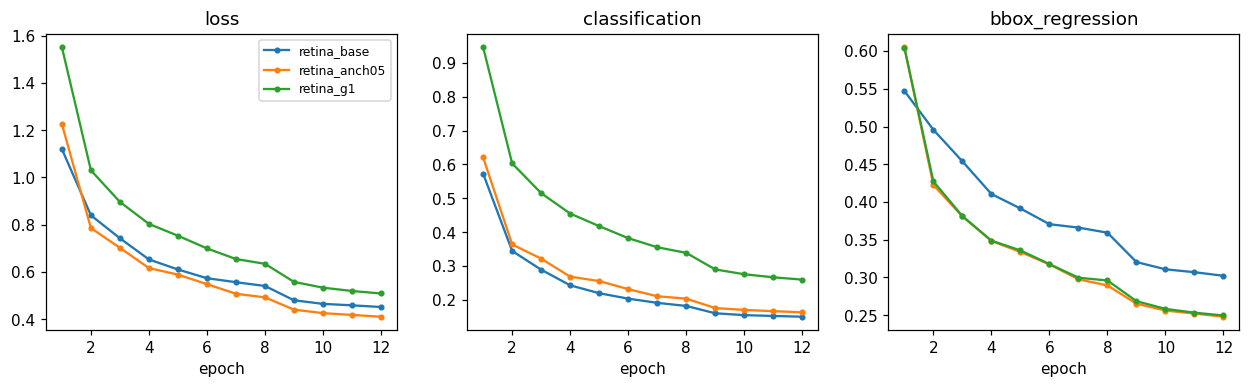

In [13]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.5))
for n in names:
    done = tvt.load_done(RUN_ROOT, n)
    if 0 not in done:
        continue
    h = pd.DataFrame(done[0]["history"])
    for a, col in zip(ax, ["loss", "classification", "bbox_regression"]):
        if col in h:
            a.plot(h["epoch"], h[col], marker="o", ms=3, label=n)
            a.set_title(col)
            a.set_xlabel("epoch")
ax[0].legend(fontsize=8)
fig.savefig(IMG_DIR / "02b_retina_loss_curves.png")
plt.show()

Loss values of different experiments are not directly comparable: changing γ changes the scale of the focal loss. We compare models by mAP and use the curves only to check convergence.

**Results (RetinaNet experiments).**

| | OOF mAP | AP50 | AP75 | AP_small | AP_medium | AP_large |
|---|---|---|---|---|---|---|
| `retina_base` | 0.071 | 0.150 | 0.062 | 0.007 | 0.048 | 0.214 |
| `retina_anch05` | 0.080 | 0.191 | 0.057 | 0.018 | 0.071 | 0.191 |
| `retina_g1` | **0.083** | **0.199** | 0.061 | **0.019** | **0.074** | 0.196 |

- **Smaller anchors help, as the anchor analysis predicted.** AP_small almost triples (0.007 → 0.018), AP_medium rises from 0.048 to 0.071. Large objects get worse (AP_large 0.214 → 0.191, bus 0.11 → 0.07) because they now get fewer positive anchors.
- **Focal γ = 1 is better than γ = 2.** The gain is small (+0.003 OOF mAP) but mAP improves on all three folds. With hundreds of positives per frame the imbalance is less extreme than on COCO, so strong down-weighting is not needed. Large objects partly recover (bus 0.07 → 0.09).
- **Speed does not change** (about 22.5 FPS, 7.1 min training per fold).
- The loss curves flatten after the LR drop at epoch 8, so 12 epochs are enough to converge.
- Best RetinaNet: **`retina_g1`** (anchors ×0.5 + γ = 1). Tuning gave +0.012 OOF mAP over the baseline.

## 8. RetinaNet vs Faster R-CNN
Results of both models are taken from the shared `results.csv`. We compare the initial and tuned RetinaNet with the initial and best Faster R-CNN, broken down by object size (COCO: small < 32², medium < 96², large above, in original pixels) and by class.

In [14]:
ALL_RESULTS = WORK / "results_all.csv"
ALL_RESULTS.unlink(missing_ok=True)
try:
    urllib.request.urlretrieve(REPO_RAW + "results.csv", ALL_RESULTS)
except Exception as e:
    print("repo results.csv not available:", e)
if RESULTS.exists():
    common.merge_results(str(RESULTS), str(ALL_RESULTS))
rt = tvt.summary(ALL_RESULTS, model="retinanet") if ALL_RESULTS.exists() else pd.DataFrame()
fr = tvt.summary(ALL_RESULTS, model="faster_rcnn") if ALL_RESULTS.exists() else pd.DataFrame()
if len(fr):
    fr = fr[~fr.index.str.contains("_prop")]
for t in (rt, fr):
    num = t.select_dtypes("number").columns
    t[num] = t[num].where(t[num] >= 0)
RETINA_BEST = rt["mAP_oof"].idxmax() if len(rt) else None
FRCNN_BEST = (fr["mAP_oof"].idxmax() if FRCNN_EXPERIMENT == "auto" else FRCNN_EXPERIMENT) if len(fr) else None
picks = {}
if "retina_base" in rt.index:
    picks["RetinaNet initial (retina_base)"] = rt.loc["retina_base"]
if RETINA_BEST is not None and RETINA_BEST != "retina_base":
    picks[f"RetinaNet tuned ({RETINA_BEST})"] = rt.loc[RETINA_BEST]
if "frcnn_base" in fr.index and FRCNN_BEST != "frcnn_base":
    picks["Faster R-CNN initial (frcnn_base)"] = fr.loc["frcnn_base"]
if FRCNN_BEST is not None:
    picks[f"Faster R-CNN tuned ({FRCNN_BEST})"] = fr.loc[FRCNN_BEST]
cmp = pd.DataFrame(picks).T
if len(cmp):
    SIZE_M = ["mAP", "AP50", "AP75", "AP_small", "AP_medium", "AP_large", "AR500"]
    cmp_table = pd.DataFrame({m: cmp[f"{m}_oof"].astype(float).round(4) for m in SIZE_M})
    cmp_table["mAP mean±std"] = [f"{a:.4f} ± {b:.4f}" for a, b in zip(cmp["mAP_mean"], cmp["mAP_std"])]
    cmp_table["FPS"] = cmp["fps"].astype(float).round(1)
    cmp_table["train min/fold"] = cmp["train_min"].astype(float).round(1)
    cmp_table.to_csv(WORK / "02b_retina_vs_frcnn.csv")
    display(cmp_table)
    display(cmp[[c for c in PER_CLASS if c in cmp]].astype(float).round(4))
else:
    print("no logged runs to compare yet")

,mAP,AP50,AP75,AP_small,AP_medium,AP_large,AR500,mAP mean±std,FPS,train min/fold
RetinaNet initial (retina_base),0.0707,0.1497,0.0620,0.0067,0.0481,0.2135,0.1844,0.0757 ± 0.0026,22.4,7.1
RetinaNet tuned (retina_g1),0.0831,0.1988,0.0609,0.0187,0.0739,0.1961,0.2207,0.0875 ± 0.0049,22.5,7.1
Faster R-CNN initial (frcnn_base),0.1131,0.2501,0.0900,0.0307,0.0929,0.2446,0.2603,0.1188 ± 0.0036,24.6,9.2
Faster R-CNN tuned (frcnn_anch05),0.1158,0.2637,0.0880,0.0344,0.1023,0.2368,0.2744,0.1208 ± 0.0039,23.2,9.8


,AP_person,AP_bicycle,AP_car,AP_van,AP_truck,AP_tricycle,AP_bus,AP_motor
RetinaNet initial (retina_base),0.0658,0.0037,0.2201,0.0606,0.0183,0.0600,0.1106,0.0333
RetinaNet tuned (retina_g1),0.0883,0.0068,0.2816,0.0675,0.0151,0.0719,0.0865,0.0502
Faster R-CNN initial (frcnn_base),0.1170,0.0126,0.3094,0.0950,0.0369,0.0868,0.1814,0.0661
Faster R-CNN tuned (frcnn_anch05),0.1326,0.0171,0.3323,0.0933,0.0332,0.0952,0.1502,0.0759


Metrics by object size (error bars = std over folds) and per-class AP difference: best RetinaNet minus best Faster R-CNN.

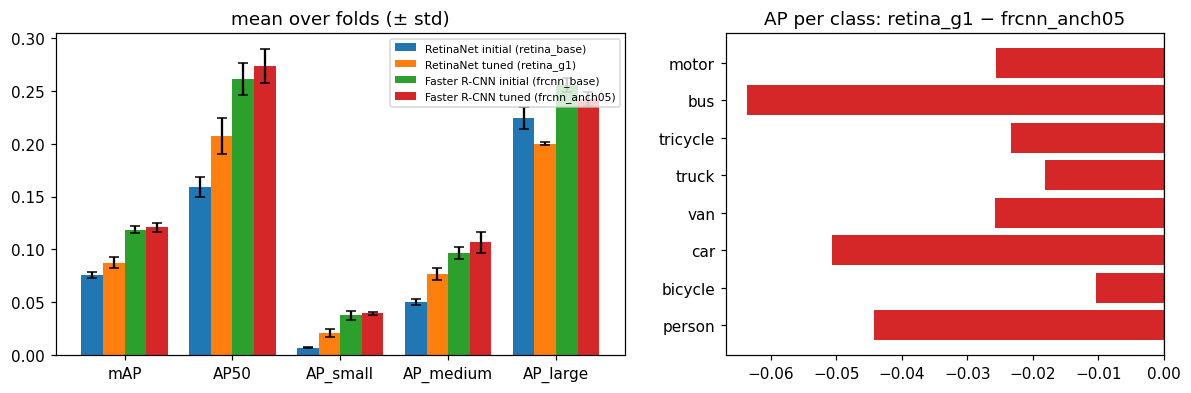

In [15]:
if len(cmp):
    fig, ax = plt.subplots(1, 2, figsize=(13, 3.8), gridspec_kw={"width_ratios": [1.3, 1]})
    ms = ["mAP", "AP50", "AP_small", "AP_medium", "AP_large"]
    x = np.arange(len(ms))
    w = 0.8 / len(cmp)
    for i, (n, r) in enumerate(cmp.iterrows()):
        ax[0].bar(x + i * w, [float(r[f"{m}_mean"]) for m in ms], w,
                  yerr=[float(r[f"{m}_std"]) for m in ms], capsize=3, label=n)
    ax[0].set_xticks(x + w * (len(cmp) - 1) / 2, ms)
    ax[0].set_title("mean over folds (± std)")
    ax[0].legend(fontsize=7)
    if RETINA_BEST is not None and FRCNN_BEST is not None:
        d = (rt.loc[RETINA_BEST, PER_CLASS].astype(float) - fr.loc[FRCNN_BEST, PER_CLASS].astype(float))
        ax[1].barh([c[3:] for c in PER_CLASS], d.values, color=np.where(d.values >= 0, "tab:green", "tab:red"))
        ax[1].axvline(0, color="k", lw=0.8)
        ax[1].set_title(f"AP per class: {RETINA_BEST} − {FRCNN_BEST}")
    fig.savefig(IMG_DIR / "02b_retina_vs_frcnn.png")
    plt.show()

**Results (RetinaNet vs Faster R-CNN).**

| | OOF mAP | AP50 | AP75 | AP_small | AP_medium | AP_large | FPS |
|---|---|---|---|---|---|---|---|
| RetinaNet tuned (`retina_g1`) | 0.083 | 0.199 | 0.061 | 0.019 | 0.074 | 0.196 | 22.5 |
| Faster R-CNN tuned (`frcnn_anch05`) | **0.116** | **0.264** | **0.088** | **0.034** | **0.102** | **0.237** | 23.2 |

- **Faster R-CNN wins on every metric and every class.** Even the untuned Faster R-CNN (0.113) is better than the tuned RetinaNet.
- **The biggest gap is in localization (AP75: 0.088 vs 0.061).** RetinaNet predicts each box once, from the features at the anchor. Faster R-CNN refines the box a second time from features pooled exactly over the proposal (RoIAlign).
- **Small objects (AP_small: 0.034 vs 0.019).** The RPN gives each object many proposals, and the second stage trains on a balanced sample of 512 RoIs per image. RetinaNet has only 1–2 positive anchors per small object among about 46,000 anchors.
- **RetinaNet is not faster here.** With `score_thresh=0.001`, each of its 5 feature levels sends up to 1000 candidates to NMS, and its heads run 4 conv layers on the large P3 map. It does train a bit faster (7.1 vs 9.8 min per fold), because there is no RoI head.

### 8.1 What changes without a proposal stage
**1. Background vs object imbalance.** In Faster R-CNN, the RPN removes almost all background, and the second stage learns from 512 RoIs per image with 25% positives. RetinaNet classifies every anchor: about 46,000 per frame, of which only a few hundred are positive (section 5). With plain cross-entropy, easy background (road, roofs) would dominate the loss, and the model would learn to predict "background" everywhere.

**2. No second refinement.** Class and box come from one pass over the anchor's features. For a 10–15 px object that is just one or two cells of P3 (stride 8), so an anchor that is slightly off is never corrected.

**3. Duplicates in dense scenes.** Neighbouring anchors produce several overlapping boxes per object, and only NMS removes them. In packed scenes NMS either keeps duplicates or removes real neighbours.

**How RetinaNet handles this:**
- **Focal loss** multiplies the loss by (1 − p)^γ, so easy background examples give almost no gradient; α balances positives and negatives. The loss is normalised by the number of positives, not anchors.
- **Prior bias init (π = 0.01):** at the start every anchor has a low score, so the first iterations are not swamped by huge background loss.
- Anchors between the two IoU thresholds are ignored.
- Anchors sized for the data (our ×0.5 experiment) give small objects more positives.

Further fixes that we did not try here: adaptive assignment (ATSS), localization-quality scores (GFL), cascaded refinement (RefineDet), Soft-NMS.

## 9. Error analysis
We analyse the best RetinaNet (`retina_g1`). The code can also run the same analysis for Faster R-CNN, but only if its saved predictions are attached as input; in this run they were not (`compared=False`), so the analysis below is for RetinaNet only.

In [16]:
if ANALYSIS_EXPERIMENT == "auto":
    ANALYSIS_EXPERIMENT = summ["mAP_oof"].idxmax() if len(summ) else RUN_LIST[0]
acfg = get_cfg(ANALYSIS_EXPERIMENT)
apreds = tvt.load_fold_preds(RUN_ROOT, ANALYSIS_EXPERIMENT)
fpreds = tvt.load_fold_preds(RUN_ROOT, FRCNN_BEST) if FRCNN_BEST else {}
DO_ANALYSIS = DO_ANALYSIS and len(apreds) > 0
HAVE_FRCNN = DO_ANALYSIS and sorted(fpreds) == sorted(apreds)
print(f"analysis of {ANALYSIS_EXPERIMENT}, folds {sorted(apreds)}, enabled={DO_ANALYSIS}; "
      f"Faster R-CNN {FRCNN_BEST}: folds {sorted(fpreds)}, compared={HAVE_FRCNN}")

analysis of retina_g1, folds [0, 1, 2], enabled=True; Faster R-CNN frcnn_anch05: folds [], compared=False


### 9.1 Score threshold
Focal-loss scores and Faster R-CNN softmax scores are calibrated differently, so one fixed threshold would be unfair. For each model we pick the threshold with the best F1 (IoU ≥ 0.5, same class), using every 4th out-of-fold frame.

In [17]:
if DO_ANALYSIS:
    oof_ids = np.concatenate([common.fold_images(images, splits, k, "val", acfg.eval_stride)["img_id"].to_numpy()
                              for k in sorted(apreds)])
    models = {ANALYSIS_EXPERIMENT: pd.concat(apreds.values(), ignore_index=True)}
    if HAVE_FRCNN:
        models[FRCNN_BEST] = pd.concat(fpreds.values(), ignore_index=True)
    thr, thr_tabs = {}, {}
    for n, p in models.items():
        thr[n], thr_tabs[n] = tvt.f1_threshold(p, images, anns, oof_ids)
    display(pd.concat(thr_tabs, axis=1).round(3))
    print("F1-optimal thresholds:", thr)

retina_g1                             
    precision recall     f1 dets_per_frame
thr                                       
0.1     0.262  0.524  0.350         90.196
0.2     0.442  0.435  0.439         44.520
0.3     0.578  0.364  0.447         28.501
0.4     0.676  0.309  0.424         20.655
0.5     0.753  0.263  0.390         15.775
0.6     0.814  0.223  0.350         12.363

F1-optimal thresholds: {'retina_g1': 0.3}


### 9.2 Error types
Detections above the threshold are matched greedily to GT boxes (IoU ≥ 0.5, same class). False positives are split into:
- `cls` — overlaps a GT box of another class;
- `loc` — right class, but 0.1 ≤ IoU < 0.5;
- `dup` — the GT box was already found;
- `bkg` — background.

Detections that lie mostly inside ignored regions are dropped. Sizes are in original pixels.

In [18]:
if DO_ANALYSIS:
    errs, rows = {}, {}
    for n, p in models.items():
        gt, dt = tvt.error_analysis(p, images, anns, oof_ids, score_thr=thr[n])
        gt["density"] = pd.cut(gt["n_in_frame"], [0, 20, 50, 100, 1000], labels=["≤20", "21-50", "51-100", ">100"])
        errs[n] = (gt, dt)
        rows[n] = {"thr": thr[n], "recall": gt["matched"].mean(),
                   "precision": (dt["type"] == "tp").mean() if len(dt) else np.nan,
                   "dets/frame": len(dt) / len(oof_ids),
                   **dt["type"].value_counts(normalize=True).rename(lambda s: f"dets {s}").to_dict()}
    gt, dt = errs[ANALYSIS_EXPERIMENT]
    display(pd.DataFrame(rows).T.round(3))

,thr,recall,precision,dets/frame,dets tp,dets loc,dets cls,dets bkg,dets dup
retina_g1,0.3,0.364,0.578,28.542,0.578,0.149,0.136,0.121,0.017


Recall by object size, occlusion level and number of objects in the frame, plus which class each missed object was confused with.

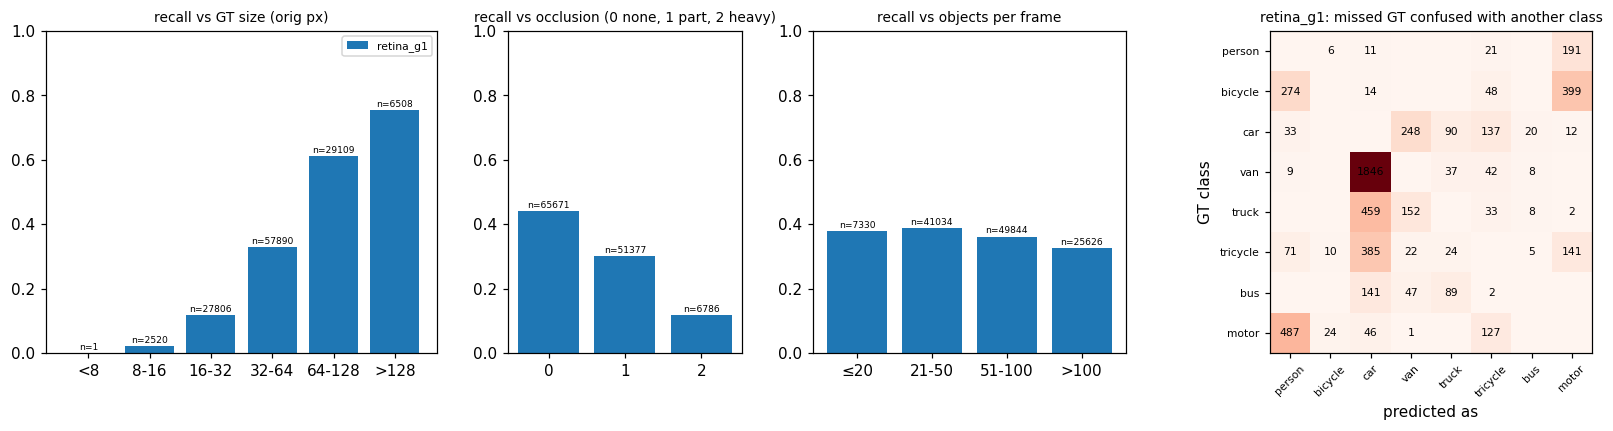

In [19]:
if DO_ANALYSIS:
    fig, ax = plt.subplots(1, 4, figsize=(19, 3.8), gridspec_kw={"width_ratios": [1, 0.6, 0.8, 1.2]})
    for a, col, title in zip(ax[:3], ["size_bin", "occlusion", "density"],
                             ["GT size (orig px)", "occlusion (0 none, 1 part, 2 heavy)", "objects per frame"]):
        w = 0.8 / len(errs)
        for i, (n, (g, _)) in enumerate(errs.items()):
            r = g.groupby(col, observed=True)["matched"].agg(["mean", "size"])
            xs = np.arange(len(r)) + i * w
            a.bar(xs, r["mean"], w, label=n)
            if i == 0:
                for xx, v, s in zip(xs, r["mean"], r["size"]):
                    a.text(xx, v + 0.01, f"n={s}", ha="center", fontsize=6)
            a.set_xticks(np.arange(len(r)) + w * (len(errs) - 1) / 2, r.index.astype(str))
        a.set_title(f"recall vs {title}", fontsize=9)
        a.set_ylim(0, 1)
    ax[0].legend(fontsize=7)
    conf = gt[gt["confused_with"] >= 0]
    cm = pd.crosstab(conf["cls"], conf["confused_with"]).reindex(index=range(8), columns=range(8), fill_value=0)
    ax[3].imshow(cm.values, cmap="Reds")
    for (i, j), v in np.ndenumerate(cm.values):
        if v:
            ax[3].text(j, i, v, ha="center", va="center", fontsize=7)
    ax[3].set_xticks(range(8), common.CLASSES, rotation=45, fontsize=7)
    ax[3].set_yticks(range(8), common.CLASSES, fontsize=7)
    ax[3].set_xlabel("predicted as")
    ax[3].set_ylabel("GT class")
    ax[3].set_title(f"{ANALYSIS_EXPERIMENT}: missed GT confused with another class", fontsize=9)
    fig.savefig(IMG_DIR / "02b_retina_error_breakdown.png")
    plt.show()

**Results (error types).** At the best threshold (0.3), recall is 0.36 and precision 0.58, with about 29 detections per frame.
- **Small objects are the main problem.** Recall by size: 8–16 px 2%, 16–32 px 12%, 32–64 px 33%, 64–128 px 61%, over 128 px 75%.
- **Occlusion hurts a lot:** recall 0.44 (none) → 0.30 (partial) → 0.12 (heavy).
- **Scene density matters less:** recall 0.38 with ≤ 20 objects vs 0.33 with more than 100.
- **False positives:** wrong localization 15%, wrong class 14%, background 12%, duplicates only 2%. NMS handles duplicates fine; most false positives are about box quality and class.
- **Typical class confusions:** van → car (by far the most common), truck → car, tricycle → car, bicycle → motor or person, motor ↔ person. These classes differ only in details that are barely visible at 10–20 px.

### 9.3 Failure cases
Four frames are picked automatically: most missed small objects (< 16 px), most class confusions, the densest frame, most duplicates.

Colours: green = correct, red = missed GT, magenta = wrong class, orange = poor localization, blue = duplicate, yellow = background false positive, gray = ignored region.

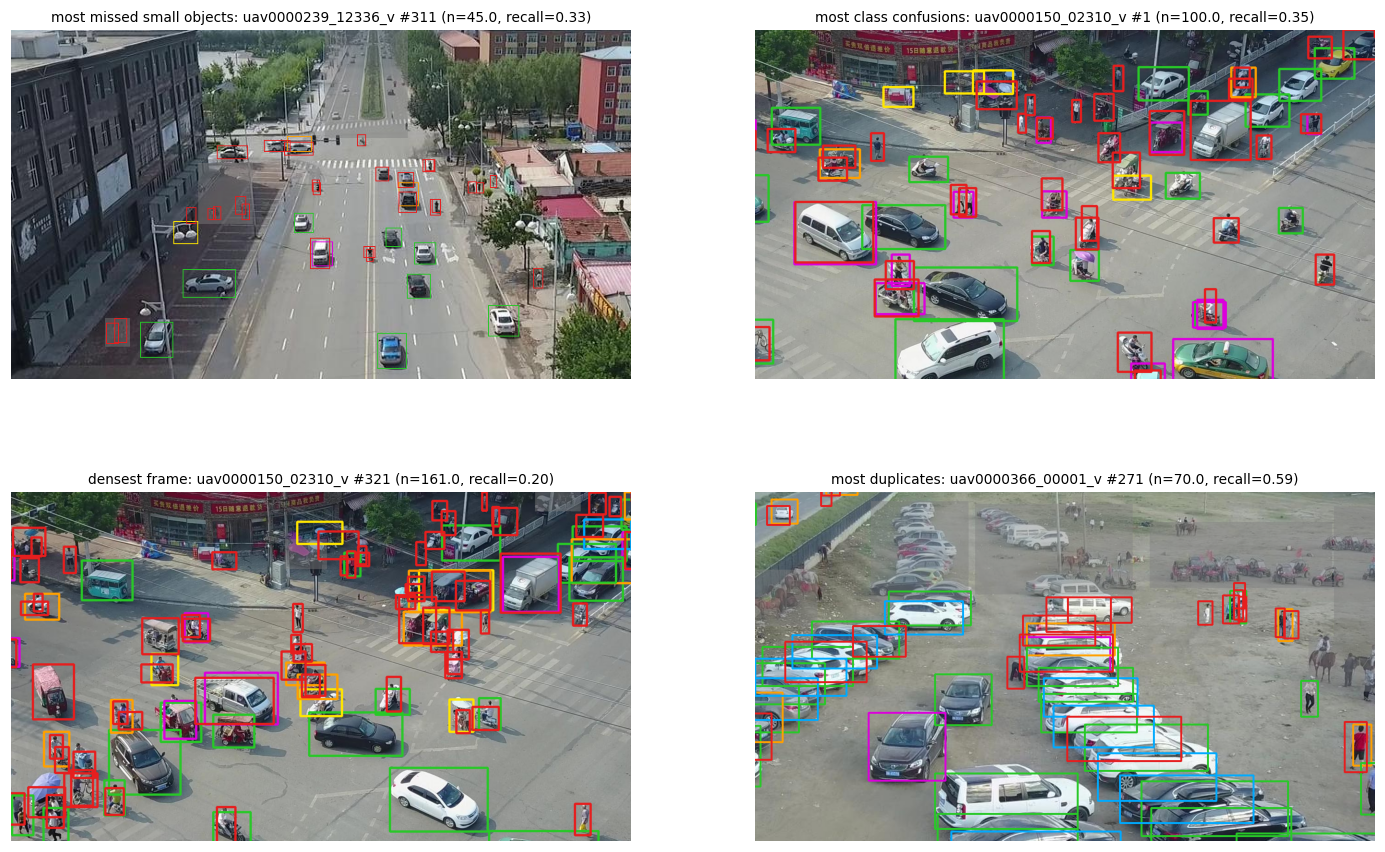

In [20]:
if DO_ANALYSIS:
    per = gt.assign(small_miss=(~gt["matched"]) & (gt["side"] < 16), conf=gt["confused_with"] >= 0)
    per = per.groupby("img_id").agg(small_miss=("small_miss", "sum"), conf=("conf", "sum"),
                                    n=("cls", "size"), recall=("matched", "mean"))
    per["dup"] = dt[dt["type"] == "dup"].groupby("img_id").size().reindex(per.index, fill_value=0) if len(dt) else 0
    cases = {"most missed small objects": per["small_miss"].idxmax(),
             "most class confusions": per["conf"].idxmax(),
             "densest frame": per["n"].idxmax(),
             "most duplicates": per["dup"].idxmax()}
    fig, ax = plt.subplots(2, 2, figsize=(16, 10))
    for a, (title, iid) in zip(ax.ravel(), cases.items()):
        a.imshow(tvt.draw_errors(iid, images, anns, gt, dt, crop="auto"))
        r = per.loc[iid]
        a.set_title(f"{title}: {images.loc[iid, 'clip']} #{images.loc[iid, 'frame_id']} "
                    f"(n={r['n']}, recall={r['recall']:.2f})", fontsize=9)
        a.axis("off")
    fig.savefig(IMG_DIR / "02b_retina_failure_cases.png")
    plt.show()

**1. Small objects** (`uav0000239_12336_v` #311, recall 0.33). Nearby cars are found, but all distant cars and pedestrians at the top of the frame are missed. At 640 px they are only 5–10 px: smaller than the smallest anchor (16 px) and about one cell of P3. Could help: higher input resolution, image slicing (SAHI), an extra P2 level.

**2. Class confusion** (`uav0000150_02310_v` #1, recall 0.35). A crossroads full of motorbikes, tricycles and people. Many magenta boxes: the object is found but the class is wrong (motor ↔ person, tricycle ↔ motor). From above, a rider and a motorbike look like one blob, and RetinaNet classifies from a single feature cell, not from the whole region.

**3. Dense scene** (same clip, #321: 161 objects, recall 0.20). Most misses are riders on motorbikes and tricycles that overlap each other. Overlapping neighbours can have IoU above 0.5 with each other, so NMS removes real detections; many objects are also heavily occluded. Could help: Soft-NMS, a higher NMS threshold.

**4. Duplicates** (`uav0000366_00001_v` #271, recall 0.59). A parking lot with cars packed side by side. Next to correct boxes there are blue duplicates and orange boxes covering two cars. Neighbouring anchors give several shifted boxes per car, there is no second stage to fix them, and NMS keeps boxes that overlap less than 0.5.

## 10. Output files
In FULL mode, merge this session's `results.csv` with the copy from the repository into `results_merged.csv` (uploaded to the repo as `notebooks/results.csv`), and list the images for the `images/` folder.

In [21]:
if MODE == "full" and RESULTS.exists():
    merged = WORK / "results_merged.csv"
    try:
        urllib.request.urlretrieve(REPO_RAW + "results.csv", merged)
    except Exception as e:
        print("repo results.csv not available:", e)
        merged.unlink(missing_ok=True)
    common.merge_results(str(RESULTS), str(merged))
    print(f"{merged}: {len(pd.read_csv(merged))} rows")
print("images:", sorted(p.name for p in IMG_DIR.glob("02b_*.png")))

/kaggle/working/results_merged.csv: 78 rows
images: ['02b_retina_anchor_matching.png', '02b_retina_comparison.png', '02b_retina_error_breakdown.png', '02b_retina_failure_cases.png', '02b_retina_loss_curves.png', '02b_retina_vs_frcnn.png']


## 11. Conclusions
- **Anchors must fit the object sizes and the stride of each level.** Default anchors give no positives to half of the VisDrone objects. Anchors ×0.5 double the share of covered objects and almost triple AP_small. Per-level k-means anchors do the opposite and cover only 15% of objects.
- **Focal γ = 1 works better than γ = 2** on this data, consistently on all folds.
- **Tuning improved RetinaNet from 0.071 to 0.083 OOF mAP**, mostly on small and medium objects.
- **RetinaNet is clearly worse than Faster R-CNN** (0.083 vs 0.116 OOF mAP), most of all in localization (AP75) and small objects. Without a proposal stage, small objects get very few good positive examples and boxes are never refined a second time. It is not even faster here.
- **So RetinaNet is not used in the final pipeline.**
- **Not tested for lack of GPU time:** IoU thresholds 0.4/0.3 (the anchor analysis shows they would double the positives) and GIoU loss.